- Source = https://www.youtube.com/watch?v=x_xoq6eY85s&t=347s
- Source = https://www.youtube.com/watch?v=jvZ0vuC9oJk&t=1425s
- This is buy and hold strategy, for each days check whether signal is +1(long - stock 2 is undervalued wrt stock 1 : long stock 2 and short stock 1) or -1(short - stock 2 is overvalued wrt stock 1 : long stock 1 and short stock 2) or 0(neutral)

### Import Libraries : Exhaustive list, not all being used

In [ ]:
from PIL import Image

import os
dir_path = r"C:\Admin\C Drive\Desktop\CQF Course\Python Labs"

In [1]:
# data manipuation
import pandas as pd
import numpy as np

# panda technical analysis 
import pandas_ta as ta

# data visualization
import matplotlib as mpl

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10,6)
plt.style.use ='seaborn'
plt.rcParams['font.size'] = 8

#-------------------------------------------------------------------------------------------------------------
# statistical visual representation
import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

#-------------------------------------------------------------------------------------------------------------
# Self organizing maps(SOM)
from minisom import MiniSom

#-------------------------------------------------------------------------------------------------------------
# K-means clustering(KMC)
from sklearn.cluster import KMeans

# scikit learn(sklearn) package is used primarily for machine learning
# always remember to perform pre-processing and model selcetion before using model implementation
import sklearn
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.model_selection import train_test_split,TimeSeriesSplit,cross_val_score,GridSearchCV,RandomizedSearchCV

from sklearn.pipeline import Pipeline

# sklearn evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

# Regression
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

# K-means clustering(KMC)
from sklearn.cluster import KMeans

# Support Vector Machine(SVM)
from sklearn.svm import SVC

# DTEM(Decision Trees and Ensemble Models) - Bagging - Random Forest
from sklearn.ensemble import RandomForestClassifier

# K nearest neighbours(KNN)
from sklearn.neighbors import KNeighborsClassifier

# Principal Component Analysis(PCA)
from sklearn.decomposition import PCA

#-------------------------------------------------------------------------------------------------------------
# DTEM(Decision Trees and Ensemble Models) - Boosting - Gradient Boosting(Extreme Gradient Boosting)
from xgboost import XGBClassifier,plot_importance,to_graphviz

#-------------------------------------------------------------------------------------------------------------
# statistical analysis & optimization
import scipy.stats as scs
import scipy.optimize as sco

# statsmodels is a Python package that provides a complement to scipy for statistical computations
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

#-------------------------------------------------------------------------------------------------------------
# Shapley values, used in DTEM
import shap

# to reload another python script 
from importlib import reload

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf
 
# float display
pd.options.display.float_format = '{:0.4f}'.format

# Trading Strategy backtesting
import ffn

# operating system
import os

# Image package
from PIL import Image

# table formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

# Pair Trading based on Cointegration

 #### Here, no restriction on accumlation of positions. For each day, it checks whether stock 2 is overvalued wrt to stocks 1 and takes positions accordingly. this is not the right approach.

In [4]:
start = '2019-12-31'
end = '2021-03-08'
fee_pct = 0.001
window = 252
adf_threshold = -2.5
stocks = ['JPM','C']
t_threshold = -2.5

prices = yf.download(stocks, start, end, progress = False)
data = prices['Close']
returns = data.pct_change(periods =1).dropna()
stock_1 = stocks[0]
stock_2 = stocks[1]

dates = np.array([])
opt_as = np.array([])
opt_bs = np.array([])
signals = np.array([])
gross_returns = np.array([])
fees = np.array([])
net_returns = np.array([])
t_stats = np.array([])

### Spread Unit Root Test and Trading Strategy

In [5]:
# at a time either we have signal as neutral(0), long(+1 : long stock 2 and short stock 1) , short(-1)
# this is daily buy-sell strategy unlike buy and hold strategy

for t in range(window, len(data)-1):
    
    # defining the unit root function: stock2 = a + b*stock1
    # this is to test unit root : dickey fuller test 
    # more negative t-statistics, more probablility of rejecting Null hypothesis - H0 : equation has unit root
    
    def unit_root(b):                                                                                                                                          
        a = np.average(data[stock_2][t-window:t] - b * data[stock_1][t-window:t])
        fair_value = a + b * data[stock_1][t-window:t]
        spread = np.array(fair_value - data[stock_2][t-window:t])
        diff_spread = spread[1:] - spread[:-1]
        
        # no constant, no trend in OLS : to achieve dynamic eqilibrius relationaship to be stable
        # this will give just 1 model estimate
        # calculating t-statistics
        
        model = sm.OLS(endog = diff_spread, exog=spread[:-1])
        results = model.fit()
        return results.params[0]/results.bse[0]
    
    date =  data.index[t]
    
    # optimising the cointegration equation parameters
        
    opt_model = sco.minimize(fun=unit_root,x0 = data[stock_2][t]/data[stock_1][t],method='Nelder-Mead')
    opt_t_statistic = opt_model.fun
    opt_b = float(opt_model.x)
    opt_a = np.average(data[stock_2][t-window:t] - opt_b * data[stock_1][t-window:t])
    
    #simulating trading--------------------------------------------------------------------------------------------
    
    fair_value = opt_a + opt_b * data[stock_1][t]
    
    if t == window:
        old_signal = 0  
        
    if opt_t_statistic > t_threshold:
        signal = 0
        gross_return = 0
    else:
        signal = np.sign(fair_value - data[stock_2][t])
        gross_return = signal*returns[stock_2][t] - signal*returns[stock_1][t]
        
    fee = fee_pct*abs(signal - old_signal)
    net_return = gross_return - fee
    
    dates = np.append(dates, date)  
    opt_as = np.append(opt_as, opt_a)
    opt_bs = np.append(opt_bs, opt_b)
    t_stats = np.append(t_stats, opt_t_statistic)    
    signals = np.append(signals,signal)
    gross_returns = np.append(gross_returns,gross_return)
    fees = np.append(fees, fee)
    net_returns = np.append(net_returns,net_return)


    print('day '+ str(data.index[t]))
    if signal == 0:
        print('no trading')
    elif  signal == 1:
        print('long position on '+stock_2+' and short position on '+stock_1)
    else:
        print('long position on '+stock_1+' and short position on '+stock_2)
    print('gross daily return: '+str(round(gross_return*100,2))+'%')
    print('net daily return: '+str(round(net_return*100,2))+'%')
    print('cumulative net return so far: '+str(round(np.prod(1+net_returns)*100-100,2))+'%')
    print('')
    
    old_signal = signal

    
output = pd.DataFrame()
output['date'] = dates
output['t_stat'] = t_stats
output['a'] = opt_as
output['b'] = opt_bs
output['fee'] = fees
output['signal'] = signals
output['gross'] = gross_returns
output['net'] = net_returns


day 2020-12-30 00:00:00
no trading
gross daily return: 0%
net daily return: 0.0%
cumulative net return so far: 0.0%

day 2020-12-31 00:00:00
no trading
gross daily return: 0%
net daily return: 0.0%
cumulative net return so far: 0.0%

day 2021-01-04 00:00:00
no trading
gross daily return: 0%
net daily return: 0.0%
cumulative net return so far: 0.0%

day 2021-01-05 00:00:00
no trading
gross daily return: 0%
net daily return: 0.0%
cumulative net return so far: 0.0%

day 2021-01-06 00:00:00
no trading
gross daily return: 0%
net daily return: 0.0%
cumulative net return so far: 0.0%

day 2021-01-07 00:00:00
no trading
gross daily return: 0%
net daily return: 0.0%
cumulative net return so far: 0.0%

day 2021-01-08 00:00:00
no trading
gross daily return: 0%
net daily return: 0.0%
cumulative net return so far: 0.0%

day 2021-01-11 00:00:00
no trading
gross daily return: 0%
net daily return: 0.0%
cumulative net return so far: 0.0%

day 2021-01-12 00:00:00
long position on JPM and short position 

### Summary

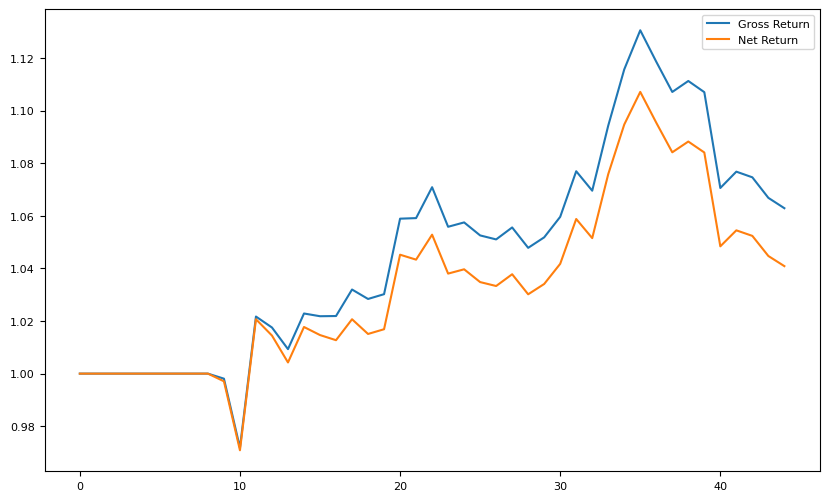

In [6]:
plt.plot(np.append(1,np.cumprod(1+gross_returns)), label = 'Gross Return')
plt.plot(np.append(1,np.cumprod(1+net_returns)),label = 'Net Return')
plt.legend()
plt.show()

## Part 2 - Advanced with Beta loading, Stop-loss and Optimal Entry

In [18]:
# specifying rolling window length
window = 22

# test statistics more than this - pair is not cointegrated
adf_threshold = -2.5

#specifying whether to perform beta-loading or not
beta_loading = 1

#strategy parameters - trading fee, optimal entry (divergence), and stop-loss
fee_pct = 0.0001             # 1bps
optimal_entry = 0.02         # 2%
stop_loss = -0.05            # -5%

#initially start in cash
signal =0
current_return = 0
position_1 = 0
position_2 = 0

#specifying the sample
start = '2019-09-28'
end = '2021-09-28'

#specifying the pair
stocks = ['XOM', 'CVX']

#specifying the market index
tickers = ['XOM', 'CVX','^GSPC']
stock_1 = tickers[0]
stock_2 = tickers[1]
market = tickers[2]

dates = np.array([])
opt_as = np.array([])
opt_bs = np.array([])
opt_t_stats = np.array([])
gross_returns = np.array([])
net_returns = np.array([])
current_returns = np.array([])
fees = np.array([])
market_returns = np.array([])
signals = np.array([])

raw_data = pd.DataFrame()


In [19]:
prices = yf.download(tickers, start, end, progress = False)
raw_data = prices['Close']

In [22]:
# have discarded last date since we dont have return information for the same
# signal = 0 : no position , +1(long) : long( stock_2) and short(stock_1) , -1(short) : short( stock_2) and long(stock_1)

for t in range(window, len(raw_data)-1):
    old_signal = signal
    old_position_1 = position_1
    old_position_2 = position_2
        
    # stock 2 = a + b*stock 1
    
    date =  raw_data.index[t]
  
    def unit_root(b):                                                                                                                                          
        a = np.average(raw_data[stock_2][t-window:t] - b * raw_data[stock_1][t-window:t])
        fair_value = a + b * raw_data[stock_1][t-window:t]
        spread = np.array(fair_value - raw_data[stock_2][t-window:t])
        diff_spread = spread[1:] - spread[:-1]
        
        # no constant, no trend in OLS : to achieve dynamic eqilibrius relationaship to be stable
        # this will give just 1 model estimate
        # calculating t-statistics
        
        model = sm.OLS(endog = diff_spread, exog=spread[:-1])
        results = model.fit()
        return results.params[0]/results.bse[0]
    
    
    # optimising the cointegration equation parameters
        
    opt_model = sco.minimize(fun=unit_root,x0 = raw_data[stock_2][t]/raw_data[stock_1][t],method='Nelder-Mead')
    opt_t_statistic = opt_model.fun
    opt_b = float(opt_model.x)
    opt_a = np.average(raw_data[stock_2][t-window:t] - opt_b * raw_data[stock_1][t-window:t])
    
    
    # simulate trading--------------------------------------------------------------------------------------------
    
    # first check whether stop-loss is violated
    
    if current_return < stop_loss:
        signal = 0
        
    # if we are already in position, check whether the equilibrium is restored, continue in position if not
    
    elif np.sign(raw_data[stock_2][t] - (opt_a + opt_b * raw_data[stock_1][t])) == old_signal:
        signal = old_signal
        
    # only trade if the pair is cointegrated  
    
    else:
        if opt_t_statistic > adf_threshold:
            signal = 0

        elif abs(raw_data[stock_2][t]/(opt_a + opt_b*raw_data[stock_1][t]) - 1) < optimal_entry:
            signal = 0
            
        else:
            signal = np.sign(raw_data[stock_2][t] - (opt_a + opt_b * raw_data[stock_1][t]))       
            
            
    # calculate strategy returns with beta loading
    
    if beta_loading == 1:
        returns_stock_2 = np.array(raw_data[stock_2][t-window:t-1])/np.array(raw_data[stock_2][t-window+1:t]) -1
        returns_stock_1 = np.array(raw_data[stock_1][t-window:t-1])/np.array(raw_data[stock_1][t-window+1:t]) -1
        returns_stock_market = np.array(raw_data[market][t-window:t-1])/np.array(raw_data[market][t-window+1:t]) -1
        
        model_1 = sm.OLS(returns_stock_1,sm.add_constant(returns_stock_market))
        result_1 = model_1.fit()
        beta_1 = result_1.params[1]
        
        model_2 = sm.OLS(returns_stock_2,sm.add_constant(returns_stock_market))
        result_2= model_2.fit()
        beta_2 = result_2.params[1]        
        
        # to make our overal position market neutral - beta_2 for stock_1 and beta_1 for stock_2
        
        position_1 = beta_2 * signal
        position_2 = beta_1 * (-signal)
    
    else:
        position_1 = signal
        position_2 = -signal
        
    # calculate returns --------------------------------------------------------------------------------------------
    gross_return = position_1*(raw_data[stock_1][t+1]/raw_data[stock_1][t]-1) + position_2*(raw_data[stock_2][t+1]/raw_data[stock_2][t]-1)
    fee = fee_pct*(abs(position_2 - old_position_2) + abs(position_1 - old_position_1))
    net_return = gross_return - fee
    market_return = raw_data[market][t+1]/raw_data[market][t]-1
    
    # means if no signal change return calcultion on same position else create a new position for return
    if signal == old_signal:
        current_return = (1 + current_return)*(1 + gross_return) -1
    else:
        current_return = gross_return
        
    # populate arrays and dataframe -----------------------------------------------------------------------------------------
    
    dates = np.append(dates,date)
    opt_as = np.append(opt_as,opt_a)
    opt_bs = np.append(opt_bs,opt_b)
    opt_t_stats = np.append(opt_t_stats,opt_t_statistic)
    fees = np.append(fees,fee)
    signals = np.append(signals, signal)
    current_returns = np.append(current_returns, current_return)
    gross_returns = np.append(gross_returns, gross_return)
    net_returns = np.append(net_returns, net_return)
    market_returns = np.append(market_returns, market_return)
    
   
output = pd.DataFrame()
output['dates'] = dates
output['t_stat'] = opt_t_stats
output['a'] = opt_as
output['b'] = opt_bs
output['fee'] = fees
output['signal'] = signals
output['current'] = current_returns
output['gross'] = gross_returns
output['net'] = net_returns
output['market'] = market_returns
    

### Summary

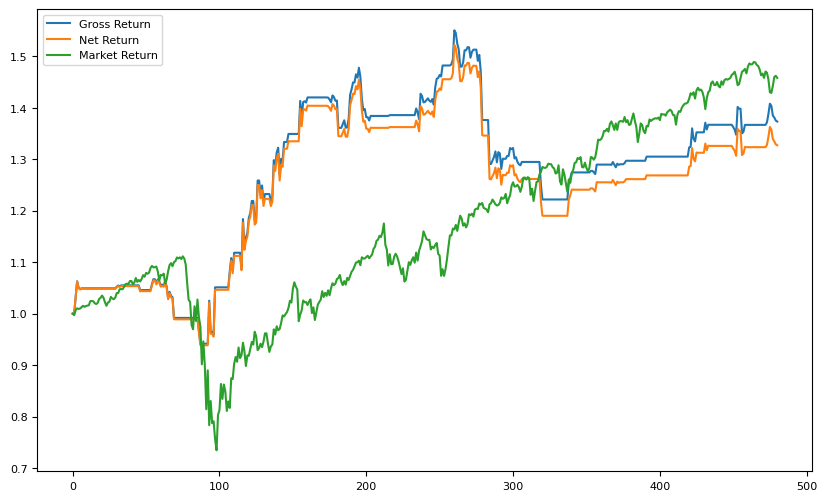

In [24]:
plt.plot(np.append(1,np.cumprod(1+gross_returns)), label = 'Gross Return')
plt.plot(np.append(1,np.cumprod(1+net_returns)),label = 'Net Return')
plt.plot(np.append(1,np.cumprod(1+market_returns)),label = 'Market Return')
plt.legend()
plt.show()

In [23]:
output.to_clipboard()